In [ ]:

import os
from google.colab import userdata

token = userdata.get("KAGGLE_API_TOKEN")
os.environ["KAGGLE_API_TOKEN"] = token

print("Kaggle Token configured successfully!")


Kaggle Token configured successfully!


In [ ]:

import kagglehub

path = kagglehub.competition_download(
    "cifar-10-res-net-architecture-challenge-dl",
    path="train_labels.csv",
    output_dir="/content/cifar10_project"
)

print("Downloaded:", path)


100%|██████████| 1.18M/1.18M [00:01<00:00, 819kB/s]

Downloaded: /content/cifar10_project/train_labels.csv


In [ ]:

import kagglehub
import pandas as pd

competition = "cifar-10-res-net-architecture-challenge-dl"

for filename in ["test.csv", "sample_submission.csv"]:
    path = kagglehub.competition_download(
        competition,
        path=filename,
        output_dir="/content/cifar10_project"
    )
    print("Downloaded:", path)

train_labels = pd.read_csv("/content/cifar10_project/train_labels.csv")
test = pd.read_csv("/content/cifar10_project/test.csv")
sample = pd.read_csv("/content/cifar10_project/sample_submission.csv")

print("\nTrain labels:", train_labels.shape)
print(train_labels.head())

print("\nTest:", test.shape)
print(test.head())

print("\nSample submission:", sample.shape)
print(sample.head())


100%|██████████| 36.0k/36.0k [00:00<00:00, 1.16MB/s]

Downloaded: /content/cifar10_project/test.csv


100%|██████████| 12.6k/12.6k [00:00<00:00, 15.4MB/s]

Downloaded: /content/cifar10_project/sample_submission.csv

Train labels: (50000, 3)
   id         filename  label
0   0  train_00000.png      6
1   1  train_00001.png      9
2   2  train_00002.png      9
3   3  train_00003.png      4
4   4  train_00004.png      1

Test: (2000, 2)
   id       filename
0   0  test_0000.png
1   1  test_0001.png
2   2  test_0002.png
3   3  test_0003.png
4   4  test_0004.png

Sample submission: (2000, 2)
   id  label
0   0      0
1   1      0
2   2      0
3   3      0
4   4      0


100%|██████████| 2.41k/2.41k [00:00<00:00, 3.25MB/s]

Downloaded: /content/cifar10_project/train_images/train_00000.png


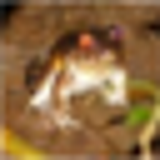

100%|██████████| 1.99k/1.99k [00:00<00:00, 2.11MB/s]

Downloaded: /content/cifar10_project/test_images/test_0000.png


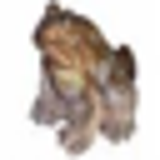

In [ ]:

import kagglehub
from PIL import Image
from IPython.display import display

competition = "cifar-10-res-net-architecture-challenge-dl"

for filename in [
    "train_images/train_00000.png",
    "test_images/test_0000.png"
]:
    path = kagglehub.competition_download(
        competition,
        path=filename,
        output_dir="/content/cifar10_project"
    )
    print("Downloaded:", path)
    display(Image.open(path).resize((160, 160)))


In [ ]:

import numpy as np
from PIL import Image
from torchvision.datasets import CIFAR10

dataset = CIFAR10(
    root="/content/cifar10_official",
    train=True,
    download=True
)

labels_match = np.array_equal(
    np.array(dataset.targets),
    train_labels["label"].to_numpy()
)

kaggle_image = np.array(
    Image.open("/content/cifar10_project/train_images/train_00000.png").convert("RGB")
)

official_image = np.array(dataset[0][0])

print("Training images:", len(dataset))
print("Labels match:", labels_match)
print("First image matches:", np.array_equal(kaggle_image, official_image))


100%|██████████| 170M/170M [23:35<00:00, 120kB/s]


Training images: 50000
Labels match: True
First image matches: True


In [ ]:

import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), "GB")
else:
    print("GPU is not enabled.")

print("Training images:", len(dataset))


PyTorch version: 2.11.0+cpu
GPU available: False
GPU is not enabled.
Training images: 50000


In [ ]:

from google.colab import drive
from pathlib import Path
import shutil

drive.mount("/content/drive")

backup = Path("/content/drive/MyDrive/DeepLearning_Project1")
backup.mkdir(parents=True, exist_ok=True)

source = Path("/content/cifar10_official/cifar-10-python.tar.gz")

if source.exists():
    shutil.copy2(source, backup / source.name)
else:
    shutil.make_archive(
        str(backup / "cifar10_official"),
        "zip",
        "/content/cifar10_official"
    )

shutil.copytree(
    "/content/cifar10_project",
    backup / "cifar10_project",
    dirs_exist_ok=True
)

print("Backup completed successfully!")
print("Saved to:", backup)


Mounted at /content/drive
Backup completed successfully!
Saved to: /content/drive/MyDrive/DeepLearning_Project1


In [ ]:

import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


GPU available: True
GPU: Tesla T4


In [ ]:

from google.colab import drive
from pathlib import Path
from torchvision.datasets import CIFAR10
import shutil
import tarfile
import pandas as pd
import numpy as np
import torch

drive.mount("/content/drive")

backup = Path("/content/drive/MyDrive/DeepLearning_Project1")
data_root = Path("/content/cifar10_official")
data_root.mkdir(parents=True, exist_ok=True)

archive = backup / "cifar-10-python.tar.gz"
zip_backup = backup / "cifar10_official.zip"

if archive.exists():
    with tarfile.open(archive, "r:gz") as f:
        f.extractall(data_root, filter="data")
elif zip_backup.exists():
    shutil.unpack_archive(str(zip_backup), str(data_root))
else:
    raise FileNotFoundError("CIFAR-10 backup not found")

shutil.copytree(
    backup / "cifar10_project",
    "/content/cifar10_project",
    dirs_exist_ok=True
)

dataset = CIFAR10(
    root=str(data_root),
    train=True,
    download=False
)

train_labels = pd.read_csv("/content/cifar10_project/train_labels.csv")
test = pd.read_csv("/content/cifar10_project/test.csv")
sample = pd.read_csv("/content/cifar10_project/sample_submission.csv")

assert len(dataset) == 50000
assert np.array_equal(np.array(dataset.targets), train_labels["label"].to_numpy())

print("Training images:", len(dataset))
print("Test images to predict:", len(test))
print("Labels verified:", True)
print("GPU:", torch.cuda.get_device_name(0))
print("Data restoration successful!")


Mounted at /content/drive
Training images: 50000
Test images to predict: 2000
Labels verified: True
GPU: Tesla T4
Data restoration successful!


In [ ]:

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import numpy as np

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

val_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

train_data = datasets.CIFAR10(
    root="/content/cifar10_official",
    train=True,
    download=False,
    transform=train_transform
)

val_data = datasets.CIFAR10(
    root="/content/cifar10_official",
    train=True,
    download=False,
    transform=val_transform
)

indices = np.random.permutation(50000)
train_indices = indices[:45000]
val_indices = indices[45000:]

train_set = Subset(train_data, train_indices)
val_set = Subset(val_data, val_indices)

train_loader = DataLoader(
    train_set,
    batch_size=128,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_set,
    batch_size=256,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

class BasicBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels, out_channels, 3,
            stride=stride, padding=1, bias=False
        )
        self.bn1 = nn.BatchNorm2d(out_channels)

        self.conv2 = nn.Conv2d(
            out_channels, out_channels, 3,
            stride=1, padding=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_channels)

        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_channels, out_channels, 1,
                    stride=stride, bias=False
                ),
                nn.BatchNorm2d(out_channels)
            )
        else:
            self.shortcut = nn.Identity()

        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        identity = self.shortcut(x)

        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = self.relu(out + identity)

        return out

class CustomResNet(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        self.in_channels = 64

        self.conv1 = nn.Conv2d(
            3, 64, 3, stride=1, padding=1, bias=False
        )
        self.bn1 = nn.BatchNorm2d(64)
        self.relu = nn.ReLU(inplace=True)

        self.layer1 = self.make_layer(64, 2, 1)
        self.layer2 = self.make_layer(128, 2, 2)
        self.layer3 = self.make_layer(256, 2, 2)

        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(256, num_classes)

    def make_layer(self, out_channels, blocks, stride):
        layers = [
            BasicBlock(self.in_channels, out_channels, stride)
        ]

        self.in_channels = out_channels

        for _ in range(1, blocks):
            layers.append(
                BasicBlock(self.in_channels, out_channels)
            )

        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.relu(self.bn1(self.conv1(x)))
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.fc(x)
        return x

model = CustomResNet().to(device)

total_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("Device:", device)
print("Training images:", len(train_set))
print("Validation images:", len(val_set))
print("Model parameters:", total_params)
print("Under 5 million:", total_params <= 5000000)

x, y = next(iter(train_loader))
print("Batch shape:", x.shape)

model.eval()
with torch.no_grad():
    output = model(x.to(device))

print("Output shape:", output.shape)
print("Model setup successful!")


Device: cuda
Training images: 45000
Validation images: 5000
Model parameters: 2777674
Under 5 million: True
Batch shape: torch.Size([128, 3, 32, 32])
Output shape: torch.Size([128, 10])
Model setup successful!


In [ ]:

import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
from pathlib import Path

epochs = 50
learning_rate = 0.001

save_dir = Path("/content/drive/MyDrive/DeepLearning_Project1/training")
save_dir.mkdir(parents=True, exist_ok=True)

best_path = save_dir / "best_resnet.pth"
last_path = save_dir / "last_checkpoint.pth"
history_path = save_dir / "training_history.csv"

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=learning_rate,
    weight_decay=0.0001
)

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=epochs
)

use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

start_epoch = 0
best_acc = 0.0
history = []

if last_path.exists():
    checkpoint = torch.load(
        last_path,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(checkpoint["model"])
    optimizer.load_state_dict(checkpoint["optimizer"])
    scheduler.load_state_dict(checkpoint["scheduler"])
    scaler.load_state_dict(checkpoint["scaler"])

    start_epoch = checkpoint["epoch"]
    best_acc = checkpoint["best_acc"]
    history = checkpoint["history"]

    print("Resuming from epoch:", start_epoch)

print("Device:", device)
print("Total epochs:", epochs)
print("Model parameters:", total_params)
print("Training started!", flush=True)

for epoch in range(start_epoch, epochs):
    model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast("cuda", enabled=use_amp):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        train_loss += loss.item() * labels.size(0)
        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.amp.autocast("cuda", enabled=use_amp):
                outputs = model(images)
                loss = criterion(outputs, labels)

            val_loss += loss.item() * labels.size(0)
            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    avg_train_loss = train_loss / train_total
    avg_val_loss = val_loss / val_total
    train_acc = 100 * train_correct / train_total
    val_acc = 100 * val_correct / val_total

    current_lr = optimizer.param_groups[0]["lr"]
    scheduler.step()

    history.append({
        "epoch": epoch + 1,
        "train_loss": avg_train_loss,
        "train_acc": train_acc,
        "val_loss": avg_val_loss,
        "val_acc": val_acc,
        "learning_rate": current_lr
    })

    if val_acc > best_acc:
        best_acc = val_acc

        torch.save({
            "model": model.state_dict(),
            "epoch": epoch + 1,
            "val_acc": val_acc,
            "parameters": total_params
        }, best_path)

        print("New best model saved!", flush=True)

    torch.save({
        "epoch": epoch + 1,
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(),
        "scaler": scaler.state_dict(),
        "best_acc": best_acc,
        "history": history
    }, last_path)

    pd.DataFrame(history).to_csv(
        history_path,
        index=False
    )

    print(
        f"Epoch [{epoch+1}/{epochs}] | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}% | "
        f"Best: {best_acc:.2f}%",
        flush=True
    )

print("Training completed!")
print("Best validation accuracy:", best_acc)
print("Best model saved to:", best_path)


Device: cuda
Total epochs: 50
Model parameters: 2777674
Training started!
New best model saved!
Epoch [1/50] | Train Loss: 1.4015 | Train Acc: 48.37% | Val Loss: 1.2425 | Val Acc: 57.00% | Best: 57.00%
New best model saved!
Epoch [2/50] | Train Loss: 0.9630 | Train Acc: 65.60% | Val Loss: 1.1652 | Val Acc: 62.52% | Best: 62.52%
New best model saved!
Epoch [3/50] | Train Loss: 0.7847 | Train Acc: 72.25% | Val Loss: 0.8440 | Val Acc: 70.94% | Best: 70.94%
New best model saved!
Epoch [4/50] | Train Loss: 0.6586 | Train Acc: 76.96% | Val Loss: 0.7099 | Val Acc: 76.22% | Best: 76.22%
Epoch [5/50] | Train Loss: 0.5661 | Train Acc: 80.38% | Val Loss: 0.7811 | Val Acc: 74.64% | Best: 76.22%
New best model saved!
Epoch [6/50] | Train Loss: 0.5043 | Train Acc: 82.52% | Val Loss: 0.7400 | Val Acc: 77.06% | Best: 77.06%
New best model saved!
Epoch [7/50] | Train Loss: 0.4538 | Train Acc: 84.21% | Val Loss: 0.5516 | Val Acc: 81.56% | Best: 81.56%
New best model saved!
Epoch [8/50] | Train Loss: 0.4

In [ ]:

import kagglehub
import pandas as pd
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
import time
import zipfile

competition = "cifar-10-res-net-architecture-challenge-dl"
base_dir = Path("/content/cifar10_project")
image_dir = base_dir / "test_images"
image_dir.mkdir(parents=True, exist_ok=True)

test_df = pd.read_csv(base_dir / "test.csv")

file_column = None

for col in test_df.columns:
    values = test_df[col].astype(str).str.lower()
    if values.str.endswith((".png", ".jpg", ".jpeg")).all():
        file_column = col
        break

if file_column is None:
    print(test_df.head())
    raise ValueError("Cannot identify image filenames in test.csv")

filenames = [
    Path(name).name
    for name in test_df[file_column].astype(str)
]

assert len(filenames) == len(set(filenames))

def download_image(name):
    target = image_dir / name

    if target.exists() and target.stat().st_size > 0:
        return name, None

    for attempt in range(4):
        try:
            result = kagglehub.competition_download(
                competition,
                path=f"test_images/{name}",
                output_dir=str(base_dir)
            )

            if not Path(result).is_file():
                raise FileNotFoundError(name)

            return name, None

        except Exception as e:
            if attempt == 3:
                return name, str(e)
            time.sleep(2 ** attempt)

print("Total images:", len(filenames))
print("Downloading test images...", flush=True)

failed = []
completed = 0

with ThreadPoolExecutor(max_workers=4) as executor:
    futures = [
        executor.submit(download_image, name)
        for name in filenames
    ]

    for future in as_completed(futures):
        name, error = future.result()
        completed += 1

        if error:
            failed.append((name, error))

        if completed % 100 == 0 or completed == len(filenames):
            print(
                f"Processed: {completed}/{len(filenames)}",
                flush=True
            )

downloaded = sum(
    (image_dir / name).is_file()
    and (image_dir / name).stat().st_size > 0
    for name in filenames
)

print("Successfully downloaded:", downloaded)
print("Failed:", len(failed))

if failed:
    print("First failures:", failed[:5])
else:
    backup_zip = Path(
        "/content/drive/MyDrive/DeepLearning_Project1/test_images.zip"
    )

    with zipfile.ZipFile(
        backup_zip, "w", zipfile.ZIP_DEFLATED
    ) as z:
        for name in filenames:
            z.write(
                image_dir / name,
                arcname=f"test_images/{name}"
            )

    print("All test images downloaded!")
    print("Backup saved:", backup_zip)


Total images: 2000


100%|██████████| 2.18k/2.18k [00:00<00:00, 2.86MB/s]


100%|██████████| 1.99k/1.99k [00:00<00:00, 3.18MB/s]


100%|██████████| 2.41k/2.41k [00:00<00:00, 3.69MB/s]


100%|██████████| 2.49k/2.49k [00:00<00:00, 7.67MB/s]


100%|██████████| 2.07k/2.07k [00:00<00:00, 1.89MB/s]


... (562 outputs left out)

100%|██████████| 1.89k/1.89k [00:00<00:00, 2.67MB/s]


100%|██████████| 2.12k/2.12k [00:00<00:00, 2.94MB/s]


100%|██████████| 1.96k/1.96k [00:00<00:00, 4.78MB/s]


Processed: 600/2000
Processed: 700/2000
Processed: 800/2000
Processed: 900/2000
Processed: 1000/2000
Processed: 1100/2000
Processed: 1200/2000
Processed: 1300/2000
Processed: 1400/2000
Processed: 1500/2000
Processed: 1600/2000
Processed: 1700/2000
Processed: 1800/2000
Processed: 1900/2000
Processed: 2000/2000
Successfully downloaded: 568
Failed: 1432
First failures: [('test_0568.png', '429 Client Error: Too Many Requests for url: https://api.kaggle.com/v1/competitions.CompetitionApiService/DownloadDataFile'), ('test_0570.png', '429 Client Error: Too Many Requests for url: https://api.kaggle.com/v1/competitions.CompetitionApiService/DownloadDataFile'), ('test_0569.png', '429 Client Error: Too Many Requests for url: https://api.kaggle.com/v1/competitions.CompetitionApiService/DownloadDataFile'), ('test_0571.png', '429 Client Error: Too Many Requests for url: https://api.kaggle.com/v1/competitions.CompetitionApiService/DownloadDataFile'), ('test_0572.png', '429 Client Error: Too Many Requ

In [ ]:

from google.colab import files
from pathlib import Path
import zipfile
import pandas as pd
import shutil

uploaded = files.upload()

zip_path = Path("test_images.zip")
output_dir = Path("/content/cifar10_project")
output_dir.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(output_dir)

test_df = pd.read_csv(output_dir / "test.csv")
image_dir = output_dir / "test_images"

missing = [
    name for name in test_df["filename"]
    if not (image_dir / name).is_file()
]

print("Expected images:", len(test_df))
print("Available images:", len(list(image_dir.glob("*.png"))))
print("Missing images:", len(missing))

assert len(test_df) == 2000
assert len(missing) == 0

backup = Path("/content/drive/MyDrive/DeepLearning_Project1/test_images.zip")
shutil.copy2(zip_path, backup)

print("Test images ready!")
print("Backup saved:", backup)


Saving test_images.zip to test_images.zip
Expected images: 2000
Available images: 2000
Missing images: 0
Test images ready!
Backup saved: /content/drive/MyDrive/DeepLearning_Project1/test_images.zip


In [ ]:

import torch
import pandas as pd
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from google.colab import files

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

base_dir = Path("/content/cifar10_project")
image_dir = base_dir / "test_images"
model_path = Path("/content/drive/MyDrive/DeepLearning_Project1/training/best_resnet.pth")
output_path = Path("/content/drive/MyDrive/DeepLearning_Project1/submission.csv")

test_df = pd.read_csv(base_dir / "test.csv")
sample_df = pd.read_csv(base_dir / "sample_submission.csv")

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

class KaggleTestDataset(Dataset):
    def __init__(self, dataframe, image_dir, transform):
        self.filenames = dataframe["filename"].tolist()
        self.image_dir = Path(image_dir)
        self.transform = transform

    def __len__(self):
        return len(self.filenames)

    def __getitem__(self, index):
        image_path = self.image_dir / self.filenames[index]
        with Image.open(image_path) as image:
            image = self.transform(image.convert("RGB"))
        return image

test_dataset = KaggleTestDataset(
    test_df,
    image_dir,
    test_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

model = CustomResNet().to(device)

checkpoint = torch.load(
    model_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model"])
model.eval()

total_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

assert total_params <= 5000000

print("GPU:", device)
print("Best model epoch:", checkpoint["epoch"])
print("Validation accuracy:", checkpoint["val_acc"])
print("Model parameters:", total_params)
print("Test images:", len(test_dataset))

predictions = []

with torch.inference_mode():
    for images in test_loader:
        images = images.to(device, non_blocking=True)
        outputs = model(images)
        predicted = outputs.argmax(dim=1)
        predictions.extend(predicted.cpu().tolist())

assert len(predictions) == len(test_df) == len(sample_df)
assert test_df["id"].tolist() == sample_df["id"].tolist()
assert all(0 <= p <= 9 for p in predictions)

submission = sample_df[["id"]].copy()
submission["label"] = predictions

assert submission.columns.tolist() == ["id", "label"]
assert not submission.isnull().any().any()

submission.to_csv(output_path, index=False)

print("\nPrediction completed!")
print("Total predictions:", len(predictions))
print("Submission shape:", submission.shape)
print("\nFirst five predictions:")
print(submission.head())
print("\nSubmission saved:", output_path)

files.download(str(output_path))


GPU: cuda
Best model epoch: 49
Validation accuracy: 92.54
Model parameters: 2777674
Test images: 2000

Prediction completed!
Total predictions: 2000
Submission shape: (2000, 2)

First five predictions:
   id  label
0   0      6
1   1      3
2   2      5
3   3      1
4   4      3

Submission saved: /content/drive/MyDrive/DeepLearning_Project1/submission.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import torch
import numpy as np
import pandas as pd
from pathlib import Path
from torchvision.datasets import CIFAR10
from torchvision import transforms
from torch.utils.data import DataLoader, Subset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_path = Path("/content/drive/MyDrive/DeepLearning_Project1/training/best_resnet.pth")

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

val_data = CIFAR10(
    root="/content/cifar10_official",
    train=True,
    download=False,
    transform=eval_transform
)

indices = np.random.RandomState(42).permutation(50000)
val_indices = indices[45000:]

val_set = Subset(val_data, val_indices)

val_loader_tta = DataLoader(
    val_set,
    batch_size=128,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

tta_model = CustomResNet().to(device)

checkpoint = torch.load(
    model_path,
    map_location=device,
    weights_only=True
)

tta_model.load_state_dict(checkpoint["model"])
tta_model.eval()

normal_correct = 0
tta_correct = 0
total = 0

print("Evaluating original model and TTA...", flush=True)

with torch.inference_mode():
    for images, labels in val_loader_tta:
        images = images.to(device)
        labels = labels.to(device)

        original_outputs = tta_model(images)

        flipped_images = torch.flip(images, dims=[3])
        flipped_outputs = tta_model(flipped_images)

        combined_outputs = (original_outputs + flipped_outputs) / 2

        normal_predictions = original_outputs.argmax(dim=1)
        tta_predictions = combined_outputs.argmax(dim=1)

        normal_correct += (normal_predictions == labels).sum().item()
        tta_correct += (tta_predictions == labels).sum().item()
        total += labels.size(0)

normal_acc = 100 * normal_correct / total
tta_acc = 100 * tta_correct / total

print("\nValidation Results")
print("Original accuracy:", f"{normal_acc:.2f}%")
print("TTA accuracy:", f"{tta_acc:.2f}%")
print("Improvement:", f"{tta_acc - normal_acc:+.2f}%")
print("Validation images:", total)

results = pd.DataFrame([
    {"method": "Original", "accuracy": normal_acc},
    {"method": "Horizontal Flip TTA", "accuracy": tta_acc}
])

results.to_csv(
    "/content/drive/MyDrive/DeepLearning_Project1/tta_comparison.csv",
    index=False
)

print("Comparison saved successfully!")


Evaluating original model and TTA...

Validation Results
Original accuracy: 92.54%
TTA accuracy: 92.90%
Improvement: +0.36%
Validation images: 5000
Comparison saved successfully!


In [ ]:

import torch
import pandas as pd
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from google.colab import files

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

base_dir = Path("/content/cifar10_project")
image_dir = base_dir / "test_images"
model_path = Path("/content/drive/MyDrive/DeepLearning_Project1/training/best_resnet.pth")

output_dir = Path("/content/drive/MyDrive/DeepLearning_Project1/tta")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / "submission.csv"

test_df = pd.read_csv(base_dir / "test.csv")
sample_df = pd.read_csv(base_dir / "sample_submission.csv")

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

class TTATestDataset(Dataset):
    def __init__(self, dataframe, image_dir, transform):
        self.filenames = dataframe["filename"].tolist()
        self.image_dir = Path(image_dir)
        self.transform = transform

    def __len__(self):
        return len(self.filenames)

    def __getitem__(self, index):
        with Image.open(self.image_dir / self.filenames[index]) as image:
            return self.transform(image.convert("RGB"))

test_dataset = TTATestDataset(
    test_df,
    image_dir,
    test_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

tta_model = CustomResNet().to(device)

checkpoint = torch.load(
    model_path,
    map_location=device,
    weights_only=True
)

tta_model.load_state_dict(checkpoint["model"])
tta_model.eval()

predictions = []

with torch.inference_mode():
    for images in test_loader:
        images = images.to(device)

        original_outputs = tta_model(images)
        flipped_outputs = tta_model(torch.flip(images, dims=[3]))

        combined_outputs = (
            original_outputs + flipped_outputs
        ) / 2

        predicted = combined_outputs.argmax(dim=1)
        predictions.extend(predicted.cpu().tolist())

assert len(predictions) == 2000
assert test_df["id"].tolist() == sample_df["id"].tolist()
assert all(0 <= p <= 9 for p in predictions)

submission = sample_df[["id"]].copy()
submission["label"] = predictions

assert submission.columns.tolist() == ["id", "label"]
assert not submission.isnull().any().any()

submission.to_csv(output_path, index=False)

print("TTA prediction completed!")
print("Total predictions:", len(predictions))
print("Submission shape:", submission.shape)
print("First five predictions:")
print(submission.head())
print("File saved:", output_path)

files.download(str(output_path))


TTA prediction completed!
Total predictions: 2000
Submission shape: (2000, 2)
First five predictions:
   id  label
0   0      6
1   1      3
2   2      5
3   3      1
4   4      3
File saved: /content/drive/MyDrive/DeepLearning_Project1/tta/submission.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image
from torchvision.datasets import CIFAR10

base_dir = Path("/content/cifar10_project")
test_df = pd.read_csv(base_dir / "test.csv")
sample_df = pd.read_csv(base_dir / "sample_submission.csv")

train_data = CIFAR10(
    root="/content/cifar10_official",
    train=True,
    download=False
)

train_pixels = train_data.data.astype(np.float32) / 255.0

test_images = []
image_modes = {}
image_sizes = {}
missing_files = []

for filename in test_df["filename"]:
    path = base_dir / "test_images" / filename

    if not path.exists():
        missing_files.append(filename)
        continue

    with Image.open(path) as img:
        image_modes[img.mode] = image_modes.get(img.mode, 0) + 1
        image_sizes[str(img.size)] = image_sizes.get(str(img.size), 0) + 1
        test_images.append(np.array(img.convert("RGB")))

assert len(missing_files) == 0
assert len(test_images) == len(test_df)

test_pixels = np.stack(test_images).astype(np.float32) / 255.0

print("DATASET CHECK")
print("Training images:", len(train_pixels))
print("Test images:", len(test_pixels))
print("Training shape:", train_pixels.shape)
print("Test shape:", test_pixels.shape)
print("Test image modes:", image_modes)
print("Test image sizes:", image_sizes)
print("Missing files:", len(missing_files))

print("\nID CHECK")
print("Unique test IDs:", test_df["id"].nunique())
print("IDs match sample:", test_df["id"].equals(sample_df["id"]))
print("Unique filenames:", test_df["filename"].nunique())

print("\nPIXEL STATISTICS")

for name, pixels in [
    ("Training", train_pixels),
    ("Kaggle Test", test_pixels)
]:
    means = pixels.mean(axis=(0, 1, 2))
    stds = pixels.std(axis=(0, 1, 2))

    print(f"\n{name}")
    print("RGB mean:", np.round(means, 4))
    print("RGB std:", np.round(stds, 4))
    print("Minimum:", round(float(pixels.min()), 4))
    print("Maximum:", round(float(pixels.max()), 4))

print("\nData check completed!")


DATASET CHECK
Training images: 50000
Test images: 2000
Training shape: (50000, 32, 32, 3)
Test shape: (2000, 32, 32, 3)
Test image modes: {'RGB': 2000}
Test image sizes: {'(32, 32)': 2000}
Missing files: 0

ID CHECK
Unique test IDs: 2000
IDs match sample: True
Unique filenames: 2000

PIXEL STATISTICS

Training
RGB mean: [0.4914 0.4822 0.4465]
RGB std: [0.247  0.2435 0.2616]
Minimum: 0.0
Maximum: 1.0

Kaggle Test
RGB mean: [0.5131 0.4979 0.4615]
RGB std: [0.2647 0.2622 0.2749]
Minimum: 0.0
Maximum: 1.0

Data check completed!


In [ ]:

import torch
import torchvision.transforms.functional as TF

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

mean_tensor = torch.tensor(
    [0.4914, 0.4822, 0.4465],
    device=device
).view(1, 3, 1, 1)

std_tensor = torch.tensor(
    [0.2470, 0.2435, 0.2616],
    device=device
).view(1, 3, 1, 1)

tta_model.eval()

original_correct = 0
shifted_correct = 0
total = 0

with torch.inference_mode():
    for images, labels in val_loader_tta:
        images = images.to(device)
        labels = labels.to(device)

        original_outputs = tta_model(images)

        raw_images = (
            images * std_tensor + mean_tensor
        ).clamp(0, 1)

        shifted_images = TF.adjust_brightness(
            raw_images, 1.05
        )

        shifted_images = TF.adjust_contrast(
            shifted_images, 1.08
        ).clamp(0, 1)

        normalized_shifted = (
            shifted_images - mean_tensor
        ) / std_tensor

        shifted_outputs = tta_model(normalized_shifted)

        original_correct += (
            original_outputs.argmax(1) == labels
        ).sum().item()

        shifted_correct += (
            shifted_outputs.argmax(1) == labels
        ).sum().item()

        total += labels.size(0)

original_acc = 100 * original_correct / total
shifted_acc = 100 * shifted_correct / total

print("Original validation accuracy:", f"{original_acc:.2f}%")
print("Brightness/contrast shifted accuracy:", f"{shifted_acc:.2f}%")
print("Accuracy change:", f"{shifted_acc-original_acc:+.2f}%")
print("Validation images:", total)
print("Robustness test completed!")


Original validation accuracy: 92.54%
Brightness/contrast shifted accuracy: 92.20%
Accuracy change: -0.34%
Validation images: 5000
Robustness test completed!
